# 82514 · Sesión S13 — El modelo de una articulación: del motor de S7 a la función de transferencia

**Bloque 5** · lunes 2 de noviembre de 2026 · 2 h  ·  IQS Universitat Ramon Llull

**Qué hace este cuaderno.** El hombro del 2R del bloque, con 1 kg en el codo y 1 kg en la mano, movido por el motor de S7 a través de una reductora de 50 y mandado en tensión: las ecuaciones simuladas tal cual, el modelo reducido a primer orden, su función de transferencia con python-control, y cómo cambia la respuesta con la postura y con la reductora.

**Se apoya en:** Lynch y Park (2017), caps. 8 y 11; Corke (2023), cap. 9; De Silva et al. (2016), caps. 1 y 4; documentación de python-control.

**Cómo usarlo en clase.** Sigue el guion de la sesión S13 en las diapositivas del bloque 5. Ejecuta la celda de instalación una sola vez al empezar; en Colab tarda unos segundos. Las celdas marcadas **Ejercicio** son para que los trabajen los estudiantes: las soluciones están al final del cuaderno.

---

In [1]:
# Ejecutar una sola vez. En Colab tarda unos segundos.
import importlib, subprocess, sys

def asegurar(mods):
    faltan = []
    for pip_name, import_name in mods:
        try:
            importlib.import_module(import_name)
        except ImportError:
            faltan.append(pip_name)
    if faltan:
        print('Instalando:', ' '.join(faltan))
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + faltan, check=False)
    else:
        print('Todo instalado ya.')

asegurar([('numpy', 'numpy'), ('scipy', 'scipy'), ('matplotlib', 'matplotlib'), ('control==0.10.2', 'control')])

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import control as ct
from scipy.integrate import solve_ivp

np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.figsize'] = (9, 3.4)
plt.rcParams['axes.grid'] = True
IQS_AZUL, IQS_VERDE = '#1B2A80', '#1FA355'
GRIS, AMBAR, NAVY = '#8A8FA8', '#B9770E', '#2E3FA3'
COMA = FuncFormatter(lambda v, p: f'{v:g}'.replace('.', ','))   # ejes con coma decimal

def ejes(*axs):
    for ax in axs:
        ax.xaxis.set_major_formatter(COMA); ax.yaxis.set_major_formatter(COMA)

print('python-control', ct.__version__, '- listo.')
if ct.__version__ != '0.10.2':
    print('AVISO: este cuaderno se probó con python-control 0.10.2. Ejecuta  !pip install -q control==0.10.2  y reinicia el entorno.')

Instalando: control==0.10.2
python-control 0.10.2 - listo.


> **Aviso para Colab.** La primera celda instala python-control 0.10.2, la versión de todo el bloque 5, en unos segundos.
>
> **En clase:** ejecuta la sección 1 sin detenerte (define los datos; sus cifras ya se vieron en las diapositivas) y trabaja la sección 2; después, el cuaderno S13b. El resto de la sección 1, la sección 3 y los tres ejercicios, en casa: las soluciones están al final.
>
> **No se sube:** este cuaderno no tiene tarea en Moodle.

## 1. El hombro con el motor de S7

*En clase, ejecuta las celdas de esta sección sin detenerte: definen los datos, y sus cifras son las de las diapositivas 5 a 7. En casa, léela entera.*

**El ejemplo de todo el bloque.** El hombro del 2R de B4 (a1 = 0,35 m, a2 = 0,2 m), ahora con masas: 1 kg en el codo (su motor y el eslabón) y 1 kg en la mano (pinza y carga), puntuales, con todo el peso en un punto. El codo está quieto: solo gira el hombro.

**El motor de S7:** 24 V, R = 2 Ω, K = K_t = K_b = 0,05, L = 1 mH y J_m = 10⁻⁴ kg·m². K es a la vez la constante de par (N·m/A) y la de contratensión (V·s/rad): en unidades del SI valen lo mismo. Sin fricción viscosa propia, como en S7. **La reductora de S6:** ideal, sin pérdidas ni holgura, con G = 50: el motor gira 50 veces más que el hombro.

**Las ecuaciones de S7, con la carga detrás de la reductora:**

- malla: `V = R·i + L·di/dt + K·ω`; la tensión se reparte entre la resistencia, la inductancia y la contratensión;
- mecánica: `J'·ω̇ = K·i − τ_L/G`; el par del motor, K·i, menos el de la carga, que llega al motor dividido por G, acelera la inercia que ve el motor;
- reductora: `ω = G·q̇` y `J' = J_m + J_L/G²`; la inercia de la carga llega al motor dividida por G².

**Las letras.** θ y ω son el ángulo y la velocidad del eje del motor; q y q̇, los de la articulación, con θ = G·q. τ_L es un par: el de la carga en la articulación. τ_e y τ_m, que salen enseguida, son tiempos. J_L es la inercia de la carga vista desde la articulación: para masas puntuales, masa por distancia al eje al cuadrado, y cambia con la postura del codo.

In [2]:
# El ejemplo del bloque 5 (diapositivas 5 a 7)
V_BUS, R, L, K, JM, G = 24.0, 2.0, 1e-3, 0.05, 1e-4, 50   # el motor de S7 y la reductora de 50
A1, A2, M1, M2, GRAV = 0.35, 0.2, 1.0, 1.0, 9.81           # el 2R de B4, 1 kg en el codo y 1 kg en la mano

def J_L(q2):
    """Inercia que ve el hombro con el codo quieto en q2 [kg·m²], masas puntuales."""
    r2 = A1**2 + A2**2 + 2*A1*A2*np.cos(q2)      # distancia de la mano al hombro, al cuadrado
    return M1*A1**2 + M2*r2

def tau_g(q1, q2):
    """Par de la gravedad en el hombro y en el codo [N·m], con el brazo en un plano vertical."""
    g1 = GRAV*(M1*A1*np.cos(q1) + M2*(A1*np.cos(q1) + A2*np.cos(q1 + q2)))
    g2 = GRAV*M2*A2*np.cos(q1 + q2)
    return np.array([g1, g2])

POSTURAS = {'estirado': 0.0, 'codo a 90°': np.pi/2, 'plegado': np.pi}
for nombre, q2 in POSTURAS.items():
    print(f"{nombre:11s} J_L = {J_L(q2):.4f} kg·m²   J' = J_m + J_L/G² = {JM + J_L(q2)/G**2:.3e} kg·m²")
print(f'factor estirado/plegado: {J_L(0)/J_L(np.pi):.2f} en la articulación, '
      f'{(JM + J_L(0)/G**2)/(JM + J_L(np.pi)/G**2):.2f} en el motor')

Jp = JM + J_L(0.0)/G**2            # J' con el brazo estirado: el caso de las diapositivas
tau_e = L/R                        # constante de tiempo eléctrica
tau_m = Jp*R/K**2                  # constante de tiempo mecánica
print(f"\ntau_e = L/R = {tau_e*1e3:.2f} ms    tau_m = J'·R/K² = {tau_m*1e3:.1f} ms    tau_m/tau_e = {tau_m/tau_e:.0f}")
tg = tau_g(0.0, 0.0)
print(f'gravedad, brazo estirado en horizontal: hombro {tg[0]:.3f} N·m, codo {tg[1]:.3f} N·m')

estirado    J_L = 0.4250 kg·m²   J' = J_m + J_L/G² = 2.700e-04 kg·m²
codo a 90°  J_L = 0.2850 kg·m²   J' = J_m + J_L/G² = 2.140e-04 kg·m²
plegado     J_L = 0.1450 kg·m²   J' = J_m + J_L/G² = 1.580e-04 kg·m²
factor estirado/plegado: 2.93 en la articulación, 1.71 en el motor

tau_e = L/R = 0.50 ms    tau_m = J'·R/K² = 216.0 ms    tau_m/tau_e = 432
gravedad, brazo estirado en horizontal: hombro 8.829 N·m, codo 1.962 N·m


Ahora las ecuaciones tal cual, sin simplificar nada: 24 V de golpe, sin gravedad (el brazo en un plano horizontal). El estado es x = (θ, ω, i). `solve_ivp`, de scipy, integra numéricamente la ecuación diferencial: se le da la función que calcula las derivadas, el intervalo de tiempo y el estado inicial. Al lado, el modelo reducido, sin L, que se deduce después de la figura: ω(t) = (V/K)·(1 − e^(−t/τ_m)).

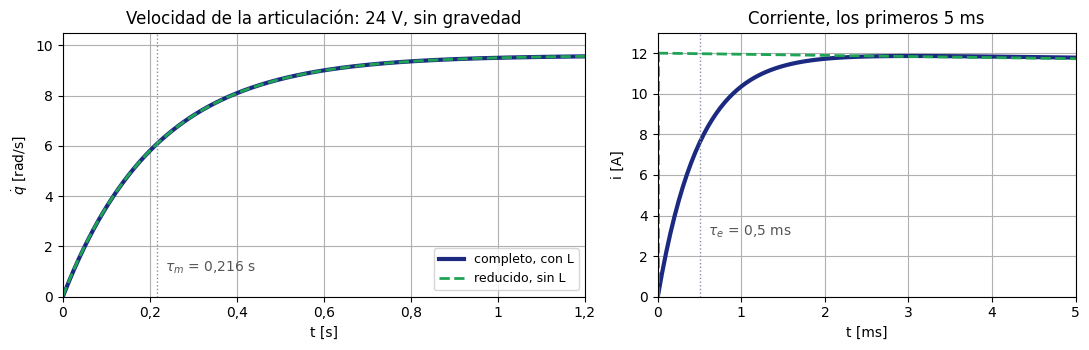

Régimen sin carga: motor V/K = 480 rad/s (4584 rpm), articulación 9.60 rad/s
Corriente del completo a los 0.5 ms: 7.58 A   (el 63 % de V/R = 12 A)
Pico de corriente del completo: 11.86 A a los 3.05 ms;  el reducido salta a 12.0 A en t = 0
Diferencia máxima de velocidad completo-reducido: 0.23 % del régimen


In [3]:
def motor3(t, x, V, tau_L=0.0):
    """Modelo completo: x = (theta, omega, i). tau_L es el par de la carga en la articulación."""
    th, w, i = x
    di = (V - R*i - K*w)/L                 # malla
    dw = (K*i - tau_L/G)/Jp                # mecánica, con la carga detrás de la reductora
    return [w, dw, di]

t = np.linspace(0, 1.2, 24001)
sol = solve_ivp(motor3, [0, 1.2], [0.0, 0.0, 0.0], args=(V_BUS,), t_eval=t,
                method='LSODA', rtol=1e-10, atol=1e-12)   # LSODA: para escalas de tiempo muy distintas
th3, w3, i3 = sol.y
w1 = (V_BUS/K)*(1 - np.exp(-t/tau_m))      # reducido: primer orden en velocidad
i1 = (V_BUS - K*w1)/R                      # su corriente: con L = 0, salta en t = 0

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1.25, 1]})
a1.plot(t, w3/G, color=IQS_AZUL, lw=3, label='completo, con L')
a1.plot(t, w1/G, color=IQS_VERDE, lw=2, ls='--', label='reducido, sin L')
a1.axvline(tau_m, color=GRIS, lw=1, ls=':'); a1.text(tau_m + 0.02, 1.0, r'$\tau_m$ = 0,216 s', color='#555')
a1.set_xlabel('t [s]'); a1.set_ylabel(r'$\dot q$ [rad/s]'); a1.set_xlim(0, 1.2); a1.set_ylim(0, 10.5)
a1.set_title('Velocidad de la articulación: 24 V, sin gravedad'); a1.legend(loc='lower right', fontsize=9)
m5 = t <= 0.005
a2.plot(t[m5]*1e3, i3[m5], color=IQS_AZUL, lw=3)
a2.plot(t[m5]*1e3, i1[m5], color=IQS_VERDE, lw=2, ls='--'); a2.plot([0, 0], [0, 12], color=IQS_VERDE, lw=2, ls='--')
a2.axvline(tau_e*1e3, color=GRIS, lw=1, ls=':'); a2.text(0.6, 3.0, r'$\tau_e$ = 0,5 ms', color='#555')
a2.set_xlabel('t [ms]'); a2.set_ylabel('i [A]'); a2.set_xlim(0, 5); a2.set_ylim(0, 13)
a2.set_title('Corriente, los primeros 5 ms')
ejes(a1, a2); plt.tight_layout(); plt.show()

k = i3.argmax()
print(f'Régimen sin carga: motor V/K = {V_BUS/K:.0f} rad/s ({V_BUS/K*60/(2*np.pi):.0f} rpm), articulación {V_BUS/K/G:.2f} rad/s')
print(f'Corriente del completo a los 0.5 ms: {np.interp(0.5e-3, t, i3):.2f} A   (el 63 % de V/R = {V_BUS/R:.0f} A)')
print(f'Pico de corriente del completo: {i3[k]:.2f} A a los {t[k]*1e3:.2f} ms;  el reducido salta a {i1[0]:.1f} A en t = 0')
print(f'Diferencia máxima de velocidad completo-reducido: {100*np.abs(w3 - w1).max()/(V_BUS/K):.2f} % del régimen')

**Por qué se puede despreciar L·di/dt.** La corriente se establece en τ_e = L/R = 0,5 ms; la velocidad, en τ_m = J'·R/K² = 216 ms, 432 veces más despacio (en S7, el motor solo daba 80 ms y 160 veces: la carga lo ha hecho más lento). Cuando la mecánica empieza a moverse, el transitorio eléctrico ya ha terminado: en la figura, las dos velocidades no se distinguen y la diferencia solo se ve en la corriente de los primeros milisegundos. Con L = 0, la malla da i = (V − K·ω)/R; sustituida en la mecánica, queda una sola ecuación, de primer orden en velocidad:

`τ_m·ω̇ + ω = V/K − (R/K²)·τ_L/G`

Despreciar L es quitar del modelo un modo que no se ve: un polo cerca de −1/τ_e = −2000 1/s, que la sección 2 calcula.

**Mandar en tensión.** En S13 el motor se manda en tensión. La contratensión K·ω frena al motor como una fricción viscosa: con L = 0, el par es K·i = K·V/R − (K²/R)·ω, y ese segundo término es un amortiguador de B_eq = K²/R = 1,25·10⁻³ N·m·s/rad. Es el amortiguador del lazo del cuaderno S13b. En S7 visteis el amplificador en modo corriente, el habitual en los servos: manda par directamente y ese freno desaparece. Volverá en S14.

**Sin gravedad.** La gravedad del brazo (8,83·cos q N·m en el hombro, con el codo estirado) depende del ángulo: no es lineal. En este cuaderno y en el S13b el lazo se estudia sin ella, con el brazo en un plano horizontal o con la gravedad compensada aparte; vuelve en S14.

## 2. La función de transferencia

*En clase.*

**La transformada de Laplace** convierte una señal del tiempo, x(t), en una función X(s) = ∫₀^∞ x(t)·e^(−s·t) dt de una variable nueva, s, en 1/s. s es compleja: tiene parte real y parte imaginaria, con j la unidad imaginaria, √−1. Integrando por partes, la derivada ẋ se transforma en s·X(s) − x(0): con condiciones iniciales nulas, **derivar es multiplicar por s**, e integrar, dividir por s.

**La función de transferencia** es la salida entre la entrada, las dos transformadas, con condiciones iniciales nulas: la ecuación diferencial se vuelve una fracción de polinomios en s. Es la segunda forma del modelo, tras la ecuación diferencial; la tercera, el espacio de estados, llega en S15. No es la «función de transferencia» de S5, que era la curva estática de un sensor: esta es dinámica. Aplicada a `τ_m·ω̇ + ω = V/K`, sin carga:

- en el motor, `Ω(s)/V(s) = (1/K)/(τ_m·s + 1)` = 20/(0,216·s + 1);
- en la articulación, `Q̇(s)/V(s) = (1/(G·K))/(τ_m·s + 1)` = 0,4/(0,216·s + 1);
- y el ángulo es la integral de la velocidad: se divide por s, un **integrador**, `Q(s)/V(s)` = 0,4/(s·(0,216·s + 1)).

**Polos y ceros.** Los polos son las raíces del denominador; los ceros, las del numerador (aquí no hay ninguno). Cada polo p es un **modo** de la respuesta, una exponencial e^(p·t): el de −1/τ_m = −4,63 se apaga con τ_m; el de 0, e^(0·t) = 1, no se apaga nunca. Con s = 0 sale la **ganancia estática**, el valor final por voltio.

En python-control, `ct.tf(numerador, denominador)` crea la función de transferencia con los coeficientes en potencias decrecientes de s; `ct.poles` da sus polos, `ct.zeros` sus ceros y `ct.dcgain` su ganancia estática.

In [4]:
Pm = ct.tf([1/K], [tau_m, 1], inputs='V', outputs='omega', name='Pm')       # Omega(s)/V(s): el motor
Pw = ct.tf([1/(G*K)], [tau_m, 1], inputs='V', outputs='qd', name='Pw')      # Qpunto(s)/V(s): la articulación
Pq = ct.tf([1/(G*K)], [tau_m, 1, 0], inputs='V', outputs='q', name='Pq')    # Q(s)/V(s): con el integrador
print(Pw); print(Pq)

for nombre, P_ in (('motor, velocidad', Pm), ('articulación, velocidad', Pw), ('articulación, ángulo', Pq)):
    z = ct.zeros(P_)
    print(f'{nombre:24s} polos {np.round(ct.poles(P_).real, 3)}   ceros: {z if len(z) else "ninguno"}'
          f'   ganancia estática {ct.dcgain(P_):.3g}')
print('Con el integrador la ganancia estática es infinita: con tensión constante, el ángulo no tiene valor final.')

<TransferFunction>: Pw
Inputs (1): ['V']
Outputs (1): ['qd']

      0.4
  -----------
  0.216 s + 1
<TransferFunction>: Pq
Inputs (1): ['V']
Outputs (1): ['q']

       0.4
  -------------
  0.216 s^2 + s
motor, velocidad         polos [-4.63]   ceros: ninguno   ganancia estática 20
articulación, velocidad  polos [-4.63]   ceros: ninguno   ganancia estática 0.4
articulación, ángulo     polos [-4.63  0.  ]   ceros: ninguno   ganancia estática inf
Con el integrador la ganancia estática es infinita: con tensión constante, el ángulo no tiene valor final.


Ahora el escalón: la entrada salta de golpe a 24 V y se queda. `ct.step_response(P, t)` simula la respuesta al escalón unitario (1 V) y `ct.step_info(P, T=t)` mide sus cifras: `RiseTime`, el tiempo de subida del 10 al 90 % del valor final; `SettlingTime`, el tiempo de establecimiento, cuando entra en la banda del 2 % y ya no sale; `Overshoot`, la sobreoscilación en %. Se le pasa una malla fina de tiempos, `t`: con la malla automática, más gruesa, las cifras salen algo peores. Las marcas de un primer orden: en τ, el 63 %; en 3·τ, el 95 %; en τ·ln 50 = 3,91·τ, el 98 %; y la subida, τ·ln 9 = 2,2·τ.

RiseTime     = 0.475 s   (tau·ln 9  = 0.475 s)
SettlingTime = 0.845 s   (tau·ln 50 = 0.845 s)
Overshoot    = 0.0 %    (un primer orden no se pasa)
Sin malla fina: RiseTime 0.482 s, SettlingTime 0.859 s
t = 1.000·tau = 0.216 s  ->  63.2 %, 6.07 rad/s
t = 3.000·tau = 0.648 s  ->  95.0 %, 9.12 rad/s
t = 3.912·tau = 0.845 s  ->  98.0 %, 9.41 rad/s


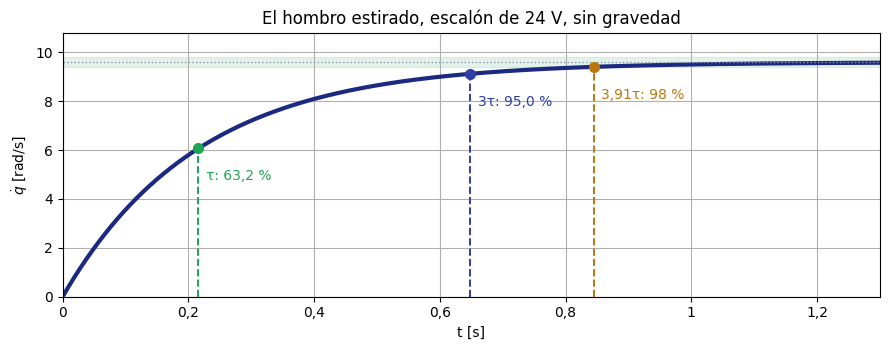

In [5]:
t = np.linspace(0, 3, 30001)               # una malla fina de tiempos, de 0 a 3 s
info = ct.step_info(Pw, T=t)
print(f"RiseTime     = {info['RiseTime']:.3f} s   (tau·ln 9  = {np.log(9)*tau_m:.3f} s)")
print(f"SettlingTime = {info['SettlingTime']:.3f} s   (tau·ln 50 = {np.log(50)*tau_m:.3f} s)")
print(f"Overshoot    = {info['Overshoot']:.1f} %    (un primer orden no se pasa)")
sin_malla = ct.step_info(Pw)
print(f"Sin malla fina: RiseTime {sin_malla['RiseTime']:.3f} s, SettlingTime {sin_malla['SettlingTime']:.3f} s")

t2, y = ct.step_response(V_BUS*Pw, np.linspace(0, 1.3, 2601))      # escalón de 24 V
fin = V_BUS*ct.dcgain(Pw)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axhspan(0.98*fin, 1.02*fin, color=IQS_VERDE, alpha=0.12)
ax.plot(t2, y, color=IQS_AZUL, lw=3); ax.axhline(fin, color=GRIS, lw=1, ls=':')
for n, rotulo, col in ((1, 'τ: 63,2 %', IQS_VERDE), (3, '3τ: 95,0 %', NAVY), (np.log(50), '3,91τ: 98 %', AMBAR)):
    tx, yy = n*tau_m, fin*(1 - np.exp(-n))
    ax.plot([tx, tx], [0, yy], color=col, lw=1.4, ls='--'); ax.plot([tx], [yy], 'o', color=col, ms=7)
    ax.text(tx + 0.012, yy - 1.3, rotulo, color=col)
    print(f't = {n:5.3f}·tau = {tx:.3f} s  ->  {100*(1 - np.exp(-n)):.1f} %, {yy:.2f} rad/s')
ax.set_xlabel('t [s]'); ax.set_ylabel(r'$\dot q$ [rad/s]'); ax.set_xlim(0, 1.3); ax.set_ylim(0, 10.8)
ax.set_title('El hombro estirado, escalón de 24 V, sin gravedad'); ejes(ax)
plt.tight_layout(); plt.show()

Y lo que se despreció. Con L, la velocidad de la articulación tiene dos polos: `Q̇(s)/V(s) = (K/G)/(L·J'·s² + R·J'·s + K²)`. Uno queda casi en −1/τ_m; el otro, el eléctrico, muy a la izquierda: su exponencial se ha apagado antes de que la mecánica empiece a moverse.

In [6]:
Pw3 = ct.tf([K/G], [L*Jp, R*Jp, K**2], inputs='V', outputs='qd', name='Pw3')   # con L: dos polos
p3 = np.sort(ct.poles(Pw3).real)
print(f'Modelo con L: polos {p3[1]:.2f} y {p3[0]:.1f} 1/s   (el rápido es {p3[0]/p3[1]:.0f} veces el lento)')
print(f'Modelo reducido: polo {ct.poles(Pw)[0].real:.2f} 1/s')
print(f'Ganancia estática: con L {ct.dcgain(Pw3):.4f}, reducido {ct.dcgain(Pw):.4f} rad/s por voltio')

Modelo con L: polos -4.64 y -1995.4 1/s   (el rápido es 430 veces el lento)
Modelo reducido: polo -4.63 1/s
Ganancia estática: con L 0.4000, reducido 0.4000 rad/s por voltio


La ganancia estática es la misma, porque en régimen permanente L·di/dt = 0 y las dos ecuaciones coinciden. Lo que cambia es un polo en −1995, 430 veces más rápido que el lento: no se ve en la respuesta en lazo abierto. En el cuaderno S13b vuelve como techo de la ganancia.

### Ejercicio 1 (en casa; en clase, sigue con el cuaderno S13b)

El mismo motor con R = 4 Ω, el doble. Sin simular, predice τ_e, τ_m, la ganancia estática de Ω(s)/V(s) y el pico de corriente al arrancar (con el rotor parado no hay contratensión). Después compruébalo en la celda de abajo, con `R4` en lugar de `R`.

In [7]:
# Ejercicio 1: el mismo motor con R = 4 ohm
R4 = 4.0
# tau_e4 = ...
# tau_m4 = ...
# ganancia estática: ...   pico de corriente: ...

## 3. La postura y la reductora

*En casa.*

La inercia que ve el hombro cambia con la postura del codo: 0,425 kg·m² estirado, 0,285 con el codo a 90° y 0,145 plegado, con la mano a 0,15 m del hombro. Un factor 2,9. Pero el motor la ve detrás de la reductora, dividida por G², sumada a la de su propio rotor: `τ_m = (J_m + J_L/G²)·R/K²`. Con G = 50, el factor que ve el motor se queda en 1,7. Es la figura de la diapositiva 11.

estirado    tau_m =  216.0 ms
codo a 90°  tau_m =  171.2 ms
plegado     tau_m =  126.4 ms


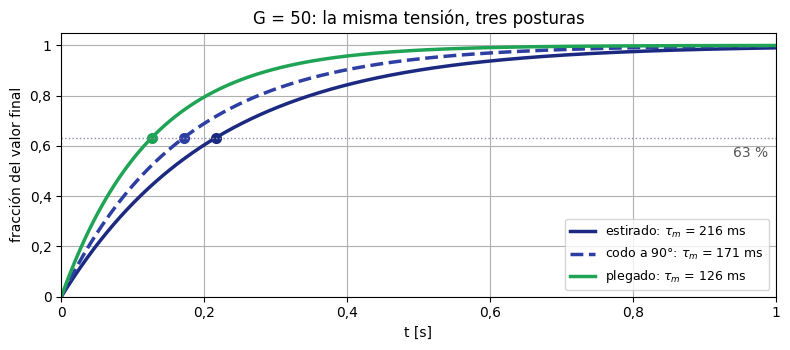

In [8]:
t = np.linspace(0, 1.0, 2001)
fig, ax = plt.subplots(figsize=(8, 3.6))
for (nombre, q2), col, ls in zip(POSTURAS.items(), (IQS_AZUL, NAVY, IQS_VERDE), ('-', '--', '-')):
    tm = (JM + J_L(q2)/G**2)*R/K**2
    print(f'{nombre:11s} tau_m = {tm*1e3:6.1f} ms')
    ax.plot(t, 1 - np.exp(-t/tm), color=col, lw=2.5, ls=ls, label=f'{nombre}: ' + r'$\tau_m$' + f' = {tm*1e3:.0f} ms')
    ax.plot([tm], [1 - np.exp(-1)], 'o', color=col, ms=7)
ax.axhline(1 - np.exp(-1), color=GRIS, lw=1, ls=':'); ax.text(0.99, 0.60, '63 %', color='#555', ha='right', va='top')
ax.set_xlabel('t [s]'); ax.set_ylabel('fracción del valor final'); ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
ax.set_title('G = 50: la misma tensión, tres posturas'); ax.legend(loc='lower right', fontsize=9); ejes(ax)
plt.tight_layout(); plt.show()

¿Y con otra reductora? Más reducción iguala las posturas y alivia la gravedad en el motor, pero divide la velocidad máxima del hombro. Las tres primeras filas de la tabla son las de la diapositiva 11.

In [9]:
print(f"{'G':>4} {'J_est [kg·m²]':>14} {'J_pleg [kg·m²]':>15} {'tau_est [ms]':>13} {'tau_pleg [ms]':>14} "
      f"{'factor':>7} {'q̇ máx [rad/s]':>14} {'tau_g/G [N·m]':>14}")
for g in (20, 50, 100, 200):
    je, jp_ = JM + J_L(0)/g**2, JM + J_L(np.pi)/g**2
    print(f'{g:4d} {je:14.4e} {jp_:15.4e} {je*R/K**2*1e3:13.1f} {jp_*R/K**2*1e3:14.1f} '
          f'{je/jp_:7.2f} {V_BUS/K/g:14.2f} {tg[0]/g:14.3f}')

   G  J_est [kg·m²]  J_pleg [kg·m²]  tau_est [ms]  tau_pleg [ms]  factor q̇ máx [rad/s]  tau_g/G [N·m]
  20     1.1625e-03      4.6250e-04         930.0          370.0    2.51          24.00          0.441
  50     2.7000e-04      1.5800e-04         216.0          126.4    1.71           9.60          0.177
 100     1.4250e-04      1.1450e-04         114.0           91.6    1.24           4.80          0.088
 200     1.1063e-04      1.0362e-04          88.5           82.9    1.07           2.40          0.044


**La gravedad como carga.** Para sostener el brazo estirado en horizontal, el motor tiene que dar el par de la gravedad dividido por G. Con el rotor parado no hay contratensión: toda la tensión cae en la resistencia, y todo lo que entra se va en calor.

In [10]:
tau_mot = tg[0]/G                      # par en el motor [N·m]
i_sost = tau_mot/K                     # corriente: par = K·i
V_sost = R*i_sost                      # tensión: parado, sin contratensión
print(f'par en el motor {tau_mot:.3f} N·m ({100*tau_mot/(K*V_BUS/R):.1f} % del par de bloqueo, {K*V_BUS/R:.1f} N·m)')
print(f'corriente {i_sost:.2f} A   tensión {V_sost:.2f} V   calor R·i² = {R*i_sost**2:.1f} W, sin moverse')

par en el motor 0.177 N·m (29.4 % del par de bloqueo, 0.6 N·m)
corriente 3.53 A   tensión 7.06 V   calor R·i² = 24.9 W, sin moverse


### Ejercicio 2 (en casa)

¿Qué G deja en 1,2 el factor estirado/plegado visto por el motor? ¿Cuánto vale entonces la velocidad máxima del hombro, y el par de la gravedad en el motor con el brazo estirado? `brentq`, de scipy, busca el cero de una función en un intervalo donde cambia de signo.

### Ejercicio 3 (en casa)

Si el motor tuviera una carga constante de 0,177 N·m (la del brazo estirado en horizontal), ¿a qué velocidad giraría con 24 V, y con qué corriente? Es la recta par-velocidad de S7.

In [11]:
# Ejercicio 2
from scipy.optimize import brentq
# f = lambda g: (JM + J_L(0)/g**2)/(JM + J_L(np.pi)/g**2) - 1.2
# G12 = brentq(f, 20, 1000)

# Ejercicio 3
# i = ...
# omega = ...   (en el motor)   q_punto = ...   (en la articulación)

---

## Soluciones

**Ejercicio 1.** τ_e = L/R = 0,25 ms, la mitad. τ_m = J'·R/K² = 0,432 s, el doble: el freno de la contratensión, B_eq = K²/R, se queda en la mitad, y con el doble de resistencia entra la mitad de corriente, así que el motor tiene la mitad de par para acelerar. La ganancia estática, 1/K, no cambia: 20 rad/s por voltio en el motor y 0,4 en la articulación; el régimen sigue siendo V/K. El pico de corriente al arrancar, V/R = 6 A, la mitad (el modelo completo se queda un poco por debajo, en 5,98 A, como los 11,86 A frente a 12 con R = 2 Ω), y el par de bloqueo, K·V/R = 0,30 N·m, también la mitad. Moraleja: la resistencia no fija la velocidad final, sino lo que tarda en llegar y el par de arranque.

**Ejercicio 2.** `brentq` da G = 112,03. Con esa reducción, la velocidad máxima del hombro es (24/0,05)/112,03 = 4,28 rad/s, menos de la mitad que con G = 50, y el par de la gravedad en el motor, 8,83/112,03 = 0,079 N·m. Igualar las posturas cuesta velocidad.

**Ejercicio 3.** Con una carga constante, la corriente es la que da ese par. Con el par exacto del brazo, 8,83/50 = 0,1766 N·m: i = 0,1766/0,05 = 3,532 A. La tensión que queda para la contratensión es 24 − R·i = 24 − 7,064 V, así que ω = (24 − 7,064)/0,05 = 338,7 rad/s en el motor y 338,7/50 = 6,77 rad/s en la articulación, frente a los 9,6 sin carga. Con 0,177 redondeado salen 3,54 A y 338,4 rad/s: en la articulación, los mismos 6,77 rad/s. Ojo: con el brazo de verdad la carga no es constante (8,83·cos q N·m en el hombro): al subir, el par de la gravedad cambia con el ángulo. Es una cota para la horizontal, no un régimen.

---

## Para llevarse de esta sesión

Modelar es escribir la ley de cada dominio y **pegarlas por K**: la misma constante da el par a partir de la corriente y la contratensión a partir de la velocidad.

**Mandar en tensión hace de la contratensión un amortiguador**, B_eq = K²/R: es lo que amortiguará el lazo de posición del cuaderno S13b. Con un amplificador de corriente, ese freno desaparece.

**Despreciar L es quitar un modo que no se ve.** τ_e = 0,5 ms frente a τ_m = 216 ms: 432 veces. La velocidad del modelo reducido no se distingue de la del completo (0,23 %).

**La función de transferencia se lee en sus polos:** −1/τ_m es la escala de la respuesta (63 % en τ, 98 % en 3,91·τ), y el polo en 0 es el integrador de la posición, al borde de la estabilidad.

**La postura cambia τ_m, y la reductora lo divide por G²:** un factor 2,9 en la articulación se queda en 1,7 en el motor con G = 50, a cambio de dividir por 50 la velocidad máxima.

*Cuaderno del curso 82514 Mecatrónica y Robótica · IQS Universitat Ramon Llull · curso 2026/27*

*© Guillermo Reyes Carmenaty · Publicado bajo [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/deed.es): puedes usarlo, adaptarlo y redistribuirlo, incluso con fines comerciales, siempre que reconozcas la autoría.*